In [1]:
import pandas as pd
import numpy as np
import os

In [2]:
import pandas as pd

path = "retraite_cotisations_2012-2024.xlsx"

df = pd.read_excel(
    path,
    engine="openpyxl"
)

print("Dimensions :", df.shape)

display(df.head())

Dimensions : (4, 14)


,En millions de dirhams,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Régimes de base,36474.279159,35867.275469,37923.033000,38756.694000,42633.974840,45106.336445,48703.852027,53424.463306,54374.478761,58142.993082,64259.651317,67287.146835,72980.553069
1,Régimes complémentaires,5395.56821,5482.053984,5972.262628,6224.459795,6737.460346,7369.388052,7948.271327,8548.911323,8841.099228,9436.619612,10516.797010,11642.238945,12512.293696
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,Cotisations de la retraite,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print("Colonnes :")
print(df.columns.tolist())

Colonnes :
['En millions de dirhams', 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   En millions de dirhams  2 non-null      str    
 1   2012                    3 non-null      object 
 2   2013                    2 non-null      float64
 3   2014                    2 non-null      float64
 4   2015                    2 non-null      float64
 5   2016                    2 non-null      float64
 6   2017                    2 non-null      float64
 7   2018                    2 non-null      float64
 8   2019                    2 non-null      float64
 9   2020                    2 non-null      float64
 10  2021                    2 non-null      float64
 11  2022                    2 non-null      float64
 12  2023                    2 non-null      float64
 13  2024                    2 non-null      float64
dtypes: float64(12), object(1), str(1)
memory usage: 580.0+ by

In [5]:
df.isna().sum()

En millions de dirhams    2
2012                      1
2013                      2
2014                      2
2015                      2
2016                      2
2017                      2
2018                      2
2019                      2
2020                      2
2021                      2
2022                      2
2023                      2
2024                      2
dtype: int64

In [14]:
import pandas as pd
import numpy as np

# 1. Lire le fichier
path = "retraite_cotisations_2012-2024.xlsx"
df = pd.read_excel(path, engine="openpyxl")

# 2. Renommer la PREMIÈRE colonne par sa position (0)
df = df.rename(columns={df.columns[0]: "regime"})

# Nettoyer les espaces inutiles f la colonne regime
df["regime"] = df["regime"].astype(str).str.strip()

# 3. Supprimer les lignes complètement vides
df = df.dropna(how="all")

# 4. Supprimer les lignes qui ne contiennent pas de données
df = df[
    df["regime"].isin([
        "Régimes de base",
        "Régimes complémentaires",
        "Total"
    ])
]

# 5. Transformer les années en lignes
df_long = df.melt(
    id_vars="regime",
    var_name="annee",
    value_name="actifs_cotisants"
)

# 6. Convertir les années en entier (avec sécurité contre le texte dans le header)
df_long["annee"] = pd.to_numeric(df_long["annee"], errors="coerce")
df_long = df_long.dropna(subset=["annee"])
df_long["annee"] = df_long["annee"].astype(int)

# 7. Convertir les actifs cotisants en numérique
df_long["actifs_cotisants"] = pd.to_numeric(
    df_long["actifs_cotisants"],
    errors="coerce"
)

# 8. Trier les données
df_long = df_long.sort_values(
    ["annee", "regime"]
).reset_index(drop=True)

# Afficher le résultat
display(df_long)

,regime,annee,actifs_cotisants
0,Régimes complémentaires,2012,5395.568210
1,Régimes de base,2012,36474.279159
2,Régimes complémentaires,2013,5482.053984
3,Régimes de base,2013,35867.275469
4,Régimes complémentaires,2014,5972.262628
5,Régimes de base,2014,37923.033000
6,Régimes complémentaires,2015,6224.459795
7,Régimes de base,2015,38756.694000
8,Régimes complémentaires,2016,6737.460346
9,Régimes de base,2016,42633.974840


In [9]:
print("Dimensions :", df_long.shape)

print("\nInformations :")
df_long.info()

print("\nValeurs manquantes :")
print(df_long.isna().sum())

Dimensions : (26, 3)

Informations :
<class 'pandas.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   regime            26 non-null     str    
 1   annee             26 non-null     int64  
 2   actifs_cotisants  26 non-null     float64
dtypes: float64(1), int64(1), str(1)
memory usage: 756.0 bytes

Valeurs manquantes :
regime              0
annee               0
actifs_cotisants    0
dtype: int64


In [10]:
print("Dimensions :", df_long.shape)

print("\nInformations :")
df_long.info()

print("\nValeurs manquantes :")
print(df_long.isna().sum())

Dimensions : (26, 3)

Informations :
<class 'pandas.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   regime            26 non-null     str    
 1   annee             26 non-null     int64  
 2   actifs_cotisants  26 non-null     float64
dtypes: float64(1), int64(1), str(1)
memory usage: 756.0 bytes

Valeurs manquantes :
regime              0
annee               0
actifs_cotisants    0
dtype: int64


In [16]:
df_long.to_csv(
    "retraite_cotisations_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

print("✅ Fichier nettoyé enregistré avec succès")

✅ Fichier nettoyé enregistré avec succès


In [1]:

import pandas as pd

path = "retraite_cotisations_2012-2024.xlsx"
df_source = pd.read_excel(path, engine="openpyxl")

print("Dimensions :", df_source.shape)
print("Colonnes :", df_source.columns.tolist())
print("\nPremières lignes :")
display(df_source.head(10))

print("\nDernières lignes :")
display(df_source.tail(10))


FileNotFoundError: [Errno 2] No such file or directory: 'retraite_cotisations_2012-2024.xlsx'

In [2]:

from pathlib import Path

print("Dossier actuel :")
print(Path.cwd())

print("\nFichiers Excel disponibles :")
for fichier in Path(".").rglob("*.xlsx"):
    if ".ipynb_checkpoints" not in str(fichier):
        print(fichier)


Dossier actuel :
C:\Users\omare\retraite au maroc

Fichiers Excel disponibles :


In [3]:

from pathlib import Path

racine = Path.home()

print("Recherche des fichiers liés à cotisations :")

for fichier in racine.rglob("*"):
    if fichier.is_file():
        nom = fichier.name.lower()

        if "cotisation" in nom or "retraite" in nom:
            if ".ipynb_checkpoints" not in str(fichier):
                print(fichier)


Recherche des fichiers liés à cotisations :
C:\Users\omare\Downloads\Rapport d'Analyse Économétrique et Simulation - Les Retraites au Maroc (2012–2030).docx
C:\Users\omare\Downloads\retraite_actifs_cotisants_2012-2024(1).xlsx
C:\Users\omare\Downloads\retraite_actifs_cotisants_2012-2024.xlsx
C:\Users\omare\retraite au maroc\retraite_actifs_cotisants.ipynb
C:\Users\omare\retraite au maroc\retraite_beneficiaires_2012-2024.xlsx.ipynb
C:\Users\omare\retraite au maroc\retraite_cotisations.ipynb
C:\Users\omare\retraite au maroc\retraite_prestations.ipynb
C:\Users\omare\retraite au maroc\data cleaning\retraite_beneficiaires_clean.csv
C:\Users\omare\retraite au maroc\data cleaning\retraite_cotisations_clean.csv
C:\Users\omare\OneDrive\Desktop\Guide_Projet_Retraites_Maroc.docx
C:\Users\omare\OneDrive\Desktop\Analyse financière et démographique du système de retraite au Maroc\retraite_actifs_cotisants_2012-2024.xlsx
C:\Users\omare\OneDrive\Desktop\Analyse financière et démographique du système de

In [4]:

import pandas as pd
from pathlib import Path

path = Path(
    r"C:\Users\omare\OneDrive\Desktop\Analyse financière et démographique du système de retraite au Maroc\retraite_cotisations_2012-2024.xlsx"
)

print("Le fichier existe :", path.exists())

if path.exists():
    df_source = pd.read_excel(path, engine="openpyxl")

    print("Dimensions :", df_source.shape)
    print("Colonnes :", df_source.columns.tolist())

    print("\nAperçu des données originales :")
    display(df_source.head(10))
else:
    print("Vérifie le chemin du fichier.")


Le fichier existe : True
Dimensions : (4, 14)
Colonnes : ['En millions de dirhams', 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

Aperçu des données originales :


,En millions de dirhams,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Régimes de base,36474.279159,35867.275469,37923.033000,38756.694000,42633.974840,45106.336445,48703.852027,53424.463306,54374.478761,58142.993082,64259.651317,67287.146835,72980.553069
1,Régimes complémentaires,5395.56821,5482.053984,5972.262628,6224.459795,6737.460346,7369.388052,7948.271327,8548.911323,8841.099228,9436.619612,10516.797010,11642.238945,12512.293696
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,Cotisations de la retraite,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:

import pandas as pd
from pathlib import Path

source = Path(
    r"C:\Users\omare\OneDrive\Desktop\Analyse financière et démographique du système de retraite au Maroc\retraite_cotisations_2012-2024.xlsx"
)

df = pd.read_excel(source, engine="openpyxl")

# Renommer la première colonne
df = df.rename(columns={df.columns[0]: "regime"})

# Nettoyer les noms des régimes
df["regime"] = df["regime"].astype(str).str.strip()

# Garder uniquement les deux régimes
regimes_valides = [
    "Régimes de base",
    "Régimes complémentaires"
]

df = df[df["regime"].isin(regimes_valides)].copy()

# Transformer les années en lignes
df_long = df.melt(
    id_vars="regime",
    var_name="annee",
    value_name="cotisations"
)

# Convertir les types
df_long["annee"] = pd.to_numeric(
    df_long["annee"], errors="coerce"
)
df_long["cotisations"] = pd.to_numeric(
    df_long["cotisations"], errors="coerce"
)

df_long = df_long.dropna(
    subset=["annee", "cotisations"]
).copy()

df_long["annee"] = df_long["annee"].astype(int)

df_long = df_long.sort_values(
    ["annee", "regime"]
).reset_index(drop=True)

print("Dimensions :", df_long.shape)
print(df_long.head(10).to_string(index=False))
print("\nValeurs manquantes :")
print(df_long.isna().sum())
print("\nDoublons année-régime :",
      df_long.duplicated(["annee", "regime"]).sum())


Dimensions : (26, 3)
                 regime  annee  cotisations
Régimes complémentaires   2012  5395.568210
        Régimes de base   2012 36474.279159
Régimes complémentaires   2013  5482.053984
        Régimes de base   2013 35867.275469
Régimes complémentaires   2014  5972.262628
        Régimes de base   2014 37923.033000
Régimes complémentaires   2015  6224.459795
        Régimes de base   2015 38756.694000
Régimes complémentaires   2016  6737.460346
        Régimes de base   2016 42633.974840

Valeurs manquantes :
regime         0
annee          0
cotisations    0
dtype: int64

Doublons année-régime : 0


In [6]:

from pathlib import Path

dossier = Path("data cleaning")
sortie = dossier / "cotisations_verification.csv"

df_long.to_csv(sortie, index=False, encoding="utf-8-sig")

print("Fichier créé :", sortie.resolve())
print("Dimensions :", df_long.shape)


Fichier créé : C:\Users\omare\retraite au maroc\data cleaning\cotisations_verification.csv
Dimensions : (26, 3)


In [7]:

import pandas as pd
from pathlib import Path

source_actifs = Path(
    r"C:\Users\omare\OneDrive\Desktop\Analyse financière et démographique du système de retraite au Maroc\retraite_actifs_cotisants_2012-2024.xlsx"
)

df_actifs_source = pd.read_excel(
    source_actifs,
    engine="openpyxl"
)

print("Dimensions :", df_actifs_source.shape)
print("Colonnes :", df_actifs_source.columns.tolist())
display(df_actifs_source.head(6))


Dimensions : (5, 14)
Colonnes : ['Unnamed: 0', 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


,Unnamed: 0,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Régimes de base,3512908,3662049.0,3790771.0,3885081.0,4047903.0,4170369.0,4270358.0,4358631.0,4127129.0,4417696.0,4656174.0,4827189.0,4935200.0
1,Régimes complémentaires,315574,322596.0,335776.0,340821.0,355150.0,366070.0,379076.0,396911.0,401002.0,417177.0,439346.0,460233.0,478623.0
2,Total,3828482,3984645.0,4126547.0,4225902.0,4403053.0,4536439.0,4649434.0,4755542.0,4528131.0,4834873.0,5095520.0,5287422.0,5413823.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,Evolution des actifs cotisants,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:

import pandas as pd
from pathlib import Path

source = Path(
    r"C:\Users\omare\OneDrive\Desktop\Analyse financière et démographique du système de retraite au Maroc\retraite_cotisations_2012-2024.xlsx"
)

dossier = Path("data cleaning")
dossier.mkdir(exist_ok=True)

df_source = pd.read_excel(source, engine="openpyxl")

# Renommer la première colonne
df_source = df_source.rename(
    columns={df_source.columns[0]: "regime"}
)

df_source["regime"] = df_source["regime"].astype(str).str.strip()

# Garder uniquement les deux régimes
regimes_valides = [
    "Régimes de base",
    "Régimes complémentaires"
]

df = df_source[df_source["regime"].isin(regimes_valides)].copy()

# Format long
df_cotisations = df.melt(
    id_vars="regime",
    var_name="annee",
    value_name="cotisations"
)

df_cotisations["annee"] = pd.to_numeric(
    df_cotisations["annee"], errors="coerce"
)
df_cotisations["cotisations"] = pd.to_numeric(
    df_cotisations["cotisations"], errors="coerce"
)

df_cotisations = df_cotisations.dropna(
    subset=["annee", "cotisations"]
).copy()

df_cotisations["annee"] = df_cotisations["annee"].astype(int)

df_cotisations = df_cotisations.sort_values(
    ["annee", "regime"]
).reset_index(drop=True)

# Enregistrer dans un nouveau fichier pour préserver l'ancien
sortie = dossier / "cotisations_clean_v2.csv"
df_cotisations.to_csv(sortie, index=False, encoding="utf-8-sig")

print("Dimensions :", df_cotisations.shape)
print(df_cotisations.head(6).to_string(index=False))
print("\nValeurs manquantes :")
print(df_cotisations.isna().sum())
print("\nDoublons :", df_cotisations.duplicated(
    ["annee", "regime"]
).sum())
print("\nFichier enregistré :", sortie.resolve())


Dimensions : (26, 3)
                 regime  annee  cotisations
Régimes complémentaires   2012  5395.568210
        Régimes de base   2012 36474.279159
Régimes complémentaires   2013  5482.053984
        Régimes de base   2013 35867.275469
Régimes complémentaires   2014  5972.262628
        Régimes de base   2014 37923.033000

Valeurs manquantes :
regime         0
annee          0
cotisations    0
dtype: int64

Doublons : 0

Fichier enregistré : C:\Users\omare\retraite au maroc\data cleaning\cotisations_clean_v2.csv


In [9]:

import pandas as pd
from pathlib import Path

dossier = Path("data cleaning")

fichiers = {
    "cotisations": "cotisations_clean_v2.csv",
    "prestations": "prestations_clean.csv",
    "placements": "placements_clean.csv"
}

for nom, fichier in fichiers.items():
    df = pd.read_csv(dossier / fichier)

    print("\n" + "=" * 50)
    print("Indicateur :", nom)
    print("Dimensions :", df.shape)
    print("Colonnes :", df.columns.tolist())
    print(df.head(4).to_string(index=False))



Indicateur : cotisations
Dimensions : (26, 3)
Colonnes : ['regime', 'annee', 'cotisations']
                 regime  annee  cotisations
Régimes complémentaires   2012  5395.568210
        Régimes de base   2012 36474.279159
Régimes complémentaires   2013  5482.053984
        Régimes de base   2013 35867.275469

Indicateur : prestations
Dimensions : (26, 3)
Colonnes : ['regime', 'annee', 'prestations']
                 regime  annee  prestations
Régimes complémentaires   2012  3381.503104
        Régimes de base   2012 28998.232149
Régimes complémentaires   2013  3911.537029
        Régimes de base   2013 32315.204000

Indicateur : placements
Dimensions : (26, 3)
Colonnes : ['regime', 'annee', 'placements']
                 regime  annee    placements
Régimes complémentaires   2012  27254.896738
        Régimes de base   2012 200606.311786
Régimes complémentaires   2013  30813.945064
        Régimes de base   2013 211026.077169


In [10]:

import pandas as pd
from pathlib import Path

# Fichier Excel original des actifs cotisants
source = Path(
    r"C:\Users\omare\OneDrive\Desktop\Analyse financière et démographique du système de retraite au Maroc\retraite_actifs_cotisants_2012-2024.xlsx"
)

df_source = pd.read_excel(source, engine="openpyxl")

# Vérifier la structure du fichier original
print("Dimensions :", df_source.shape)
print("Colonnes :", df_source.columns.tolist())
print(df_source.head(8).to_string(index=False))


Dimensions : (5, 14)
Colonnes : ['Unnamed: 0', 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
             Unnamed: 0                           2012      2013      2014      2015      2016      2017      2018      2019      2020      2021      2022      2023      2024
        Régimes de base                        3512908 3662049.0 3790771.0 3885081.0 4047903.0 4170369.0 4270358.0 4358631.0 4127129.0 4417696.0 4656174.0 4827189.0 4935200.0
Régimes complémentaires                         315574  322596.0  335776.0  340821.0  355150.0  366070.0  379076.0  396911.0  401002.0  417177.0  439346.0  460233.0  478623.0
                  Total                        3828482 3984645.0 4126547.0 4225902.0 4403053.0 4536439.0 4649434.0 4755542.0 4528131.0 4834873.0 5095520.0 5287422.0 5413823.0
                    NaN                            NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN       NaN


In [11]:

import pandas as pd
from pathlib import Path

# 1. Lire le fichier Excel original
source = Path(
    r"C:\Users\omare\OneDrive\Desktop\Analyse financière et démographique du système de retraite au Maroc\retraite_actifs_cotisants_2012-2024.xlsx"
)

df_source = pd.read_excel(source, engine="openpyxl")

# 2. Renommer la première colonne
df_source = df_source.rename(
    columns={df_source.columns[0]: "regime"}
)

# 3. Nettoyer les noms des régimes
df_source["regime"] = df_source["regime"].astype("string").str.strip()

# 4. Garder uniquement les deux régimes
regimes_valides = [
    "Régimes de base",
    "Régimes complémentaires"
]

df = df_source[df_source["regime"].isin(regimes_valides)].copy()

# 5. Transformer le tableau large en tableau long
df_clean = df.melt(
    id_vars="regime",
    var_name="annee",
    value_name="actifs_cotisants"
)

# 6. Corriger les types de données
df_clean["annee"] = pd.to_numeric(
    df_clean["annee"], errors="coerce"
)

df_clean["actifs_cotisants"] = pd.to_numeric(
    df_clean["actifs_cotisants"], errors="coerce"
)

df_clean = df_clean.dropna(
    subset=["annee", "actifs_cotisants"]
).copy()

df_clean["annee"] = df_clean["annee"].astype(int)
df_clean["actifs_cotisants"] = df_clean[
    "actifs_cotisants"
].astype("int64")

# 7. Trier les données
df_clean = df_clean.sort_values(
    ["annee", "regime"]
).reset_index(drop=True)

# 8. Enregistrer le fichier nettoyé
dossier = Path("data cleaning")
dossier.mkdir(exist_ok=True)

sortie = dossier / "actifs_cotisants_clean.csv"

df_clean.to_csv(
    sortie,
    index=False,
    encoding="utf-8-sig"
)

print("Dimensions :", df_clean.shape)
print("\nAperçu :")
print(df_clean.head(6).to_string(index=False))

print("\nAnnées :", df_clean["annee"].min(), "-", df_clean["annee"].max())
print("Valeurs manquantes :")
print(df_clean.isna().sum())

print("\nFichier enregistré :", sortie.resolve())


Dimensions : (26, 3)

Aperçu :
                 regime  annee  actifs_cotisants
Régimes complémentaires   2012            315574
        Régimes de base   2012           3512908
Régimes complémentaires   2013            322596
        Régimes de base   2013           3662049
Régimes complémentaires   2014            335776
        Régimes de base   2014           3790771

Années : 2012 - 2024
Valeurs manquantes :
regime              0
annee               0
actifs_cotisants    0
dtype: int64

Fichier enregistré : C:\Users\omare\retraite au maroc\data cleaning\actifs_cotisants_clean.csv


In [12]:

import pandas as pd
from pathlib import Path

dossier = Path("data cleaning")

# 1. Charger les fichiers nettoyés
actifs = pd.read_csv(dossier / "actifs_cotisants_clean.csv")
cotisations = pd.read_csv(dossier / "cotisations_clean_v2.csv")
prestations = pd.read_csv(dossier / "prestations_clean.csv")
placements = pd.read_csv(dossier / "placements_clean.csv")
beneficiaires = pd.read_csv(dossier / "beneficiaires_clean.csv")

# 2. Vérifier les colonnes de chaque fichier
for nom, df in {
    "actifs": actifs,
    "cotisations": cotisations,
    "prestations": prestations,
    "placements": placements,
    "beneficiaires": beneficiaires
}.items():
    print(f"{nom}: {df.shape} | {df.columns.tolist()}")

# 3. Agréger les bénéficiaires par année et régime
beneficiaires_total = (
    beneficiaires
    .groupby(["annee", "regime"], as_index=False)["beneficiaires"]
    .sum()
)

# 4. Préparer les fichiers à fusionner
fichiers = [
    actifs,
    cotisations,
    prestations,
    placements,
    beneficiaires_total
]

# 5. Vérifier l'unicité des clés avant la fusion
for df in fichiers:
    assert not df.duplicated(["annee", "regime"]).any(), (
        "Doublons détectés dans les clés année-régime"
    )

# 6. Fusionner les données
master = actifs.copy()

for df in fichiers[1:]:
    master = master.merge(
        df,
        on=["annee", "regime"],
        how="outer",
        validate="one_to_one"
    )

# 7. Trier les observations
master = master.sort_values(
    ["annee", "regime"]
).reset_index(drop=True)

# 8. Vérifier le résultat
print("\nDimensions du master dataset :", master.shape)
print("\nValeurs manquantes :")
print(master.isna().sum())

print("\nAperçu :")
print(master.head(10).to_string(index=False))

# 9. Enregistrer le fichier
sortie = dossier / "master_dataset.csv"
master.to_csv(sortie, index=False, encoding="utf-8-sig")

print("\nFichier enregistré :", sortie.resolve())


actifs: (26, 3) | ['regime', 'annee', 'actifs_cotisants']
cotisations: (26, 3) | ['regime', 'annee', 'cotisations']
prestations: (26, 3) | ['regime', 'annee', 'prestations']
placements: (26, 3) | ['regime', 'annee', 'placements']
beneficiaires: (78, 4) | ['annee', 'regime', 'categorie', 'beneficiaires']

Dimensions du master dataset : (26, 7)

Valeurs manquantes :
regime              0
annee               0
actifs_cotisants    0
cotisations         0
prestations         0
placements          0
beneficiaires       0
dtype: int64

Aperçu :
                 regime  annee  actifs_cotisants  cotisations  prestations    placements  beneficiaires
Régimes complémentaires   2012            315574  5395.568210  3381.503104  27254.896738         145828
        Régimes de base   2012           3512908 36474.279159 28998.232149 200606.311786         809308
Régimes complémentaires   2013            322596  5482.053984  3911.537029  30813.945064         152392
        Régimes de base   2013          

In [13]:

import pandas as pd
from pathlib import Path

dossier = Path("data cleaning")

# Charger le master dataset
df = pd.read_csv(dossier / "master_dataset.csv")

# Trier les données par régime et année
df = df.sort_values(["regime", "annee"]).reset_index(drop=True)

# 1. Ratio démographique
df["ratio_demographique"] = (
    df["actifs_cotisants"] / df["beneficiaires"]
)

# 2. Solde cotisations - prestations
df["solde_cotisations_prestations"] = (
    df["cotisations"] - df["prestations"]
)

# 3. Taux de couverture des prestations
df["taux_couverture_pct"] = (
    df["cotisations"] / df["prestations"] * 100
)

# 4. Évolution annuelle des variables principales
variables = [
    "actifs_cotisants",
    "beneficiaires",
    "cotisations",
    "prestations",
    "placements"
]

for variable in variables:
    df[f"evolution_{variable}_pct"] = (
        df.groupby("regime")[variable]
        .pct_change() * 100
    )

# Vérifier les résultats
colonnes_a_afficher = [
    "regime",
    "annee",
    "ratio_demographique",
    "solde_cotisations_prestations",
    "taux_couverture_pct"
]

print(df[colonnes_a_afficher].head(10).to_string(index=False))

# Enregistrer une nouvelle version
sortie = dossier / "master_dataset_indicators.csv"
df.to_csv(sortie, index=False, encoding="utf-8-sig")

print("\nDimensions :", df.shape)
print("Valeurs manquantes :")
print(df.isna().sum())
print("\nFichier enregistré :", sortie.resolve())


                 regime  annee  ratio_demographique  solde_cotisations_prestations  taux_couverture_pct
Régimes complémentaires   2012             2.164015                    2014.065106           159.561238
Régimes complémentaires   2013             2.116883                    1570.516955           140.150891
Régimes complémentaires   2014             2.156751                    1850.786376           144.905909
Régimes complémentaires   2015             2.100877                    1874.505084           143.092520
Régimes complémentaires   2016             2.105566                    2155.549346           147.044767
Régimes complémentaires   2017             2.078491                    2513.680904           151.767556
Régimes complémentaires   2018             2.091915                    2863.222867           156.306698
Régimes complémentaires   2019             2.110331                    3081.025663           156.347661
Régimes complémentaires   2020             2.058056             

In [14]:

import pandas as pd
from pathlib import Path

dossier = Path("data cleaning")

df = pd.read_csv(
    dossier / "master_dataset_indicators.csv"
)

# Variables à analyser
variables = [
    "actifs_cotisants",
    "beneficiaires",
    "cotisations",
    "prestations",
    "placements",
    "ratio_demographique",
    "solde_cotisations_prestations",
    "taux_couverture_pct"
]

# Statistiques descriptives par régime
for regime in df["regime"].unique():
    print("\n" + "=" * 65)
    print("RÉGIME :", regime)
    print("=" * 65)

    df_regime = df[df["regime"] == regime]

    print(
        df_regime[variables]
        .describe()
        .round(2)
        .T
        .to_string()
    )

# Comparer les valeurs de 2012 et 2024
print("\nÉVOLUTION ENTRE 2012 ET 2024")

for regime in df["regime"].unique():
    df_regime = df[df["regime"] == regime].set_index("annee")

    print("\nRégime :", regime)

    for variable in [
        "actifs_cotisants",
        "beneficiaires",
        "cotisations",
        "prestations",
        "placements"
    ]:
        valeur_2012 = df_regime.loc[2012, variable]
        valeur_2024 = df_regime.loc[2024, variable]

        variation = (
            (valeur_2024 / valeur_2012) - 1
        ) * 100

        print(
            f"{variable}: "
            f"2012 = {valeur_2012:,.2f} | "
            f"2024 = {valeur_2024:,.2f} | "
            f"Variation = {variation:.2f}%"
        )



RÉGIME : Régimes complémentaires
                               count       mean       std        min        25%        50%        75%        max
actifs_cotisants                13.0  385258.08  52586.96  315574.00  340821.00  379076.00  417177.00  478623.00
beneficiaires                   13.0  182413.31  24784.64  145828.00  162228.00  181210.00  201997.00  220337.00
cotisations                     13.0    8202.11   2325.30    5395.57    6224.46    7948.27    9436.62   12512.29
prestations                     13.0    5283.44   1231.74    3381.50    4349.95    5085.05    6322.75    7233.08
placements                      13.0   56210.96  20881.23   27254.90   39161.44   55059.32   71866.14   92196.28
ratio_demographique             13.0       2.11      0.04       2.06       2.09       2.11       2.14       2.17
solde_cotisations_prestations   13.0    2918.67   1129.88    1570.52    2014.07    2863.22    3113.87    5279.21
taux_couverture_pct             13.0     153.86      9.43     

In [15]:

import pandas as pd
import numpy as np
from pathlib import Path

dossier = Path("data cleaning")

df = pd.read_csv(
    dossier / "master_dataset_indicators.csv"
)

# Trier les données
df = df.sort_values(
    ["regime", "annee"]
).reset_index(drop=True)

# Recalculer les indicateurs
df["ratio_verification"] = (
    df["actifs_cotisants"] / df["beneficiaires"]
)

df["solde_verification"] = (
    df["cotisations"] - df["prestations"]
)

df["couverture_verification"] = (
    df["cotisations"] / df["prestations"] * 100
)

# Comparer les indicateurs existants aux valeurs recalculées
comparaisons = {
    "ratio_demographique": "ratio_verification",
    "solde_cotisations_prestations": "solde_verification",
    "taux_couverture_pct": "couverture_verification"
}

for ancien, nouveau in comparaisons.items():
    difference = (df[ancien] - df[nouveau]).abs()
    print(
        f"{ancien} : différence maximale = "
        f"{difference.max():.10f}"
    )

# Vérifier les valeurs de 2012 et 2024
colonnes = [
    "annee",
    "actifs_cotisants",
    "beneficiaires",
    "ratio_verification",
    "cotisations",
    "prestations",
    "solde_verification",
    "couverture_verification"
]

for regime in df["regime"].unique():
    print("\n" + "=" * 75)
    print("RÉGIME :", regime)
    print("=" * 75)

    selection = df[
        (df["regime"] == regime)
        & (df["annee"].isin([2012, 2024]))
    ]

    print(
        selection[colonnes]
        .round(3)
        .to_string(index=False)
    )

# Vérifier les variations entre 2012 et 2024
print("\nVARIATIONS 2012–2024")

variables = [
    "actifs_cotisants",
    "beneficiaires",
    "cotisations",
    "prestations",
    "placements"
]

for regime in df["regime"].unique():
    sous_df = df[df["regime"] == regime].set_index("annee")

    print("\n", regime)

    for variable in variables:
        debut = sous_df.loc[2012, variable]
        fin = sous_df.loc[2024, variable]
        variation = (fin / debut - 1) * 100

        print(f"{variable}: {variation:.2f}%")


ratio_demographique : différence maximale = 0.0000000000
solde_cotisations_prestations : différence maximale = 0.0000000000
taux_couverture_pct : différence maximale = 0.0000000000

RÉGIME : Régimes complémentaires
 annee  actifs_cotisants  beneficiaires  ratio_verification  cotisations  prestations  solde_verification  couverture_verification
  2012            315574         145828               2.164     5395.568     3381.503            2014.065                  159.561
  2024            478623         220337               2.172    12512.294     7233.079            5279.215                  172.987

RÉGIME : Régimes de base
 annee  actifs_cotisants  beneficiaires  ratio_verification  cotisations  prestations  solde_verification  couverture_verification
  2012           3512908         809308               4.341    36474.279    28998.232            7476.047                  125.781
  2024           4935200        1482677               3.329    72980.553    78656.732           -5676.17

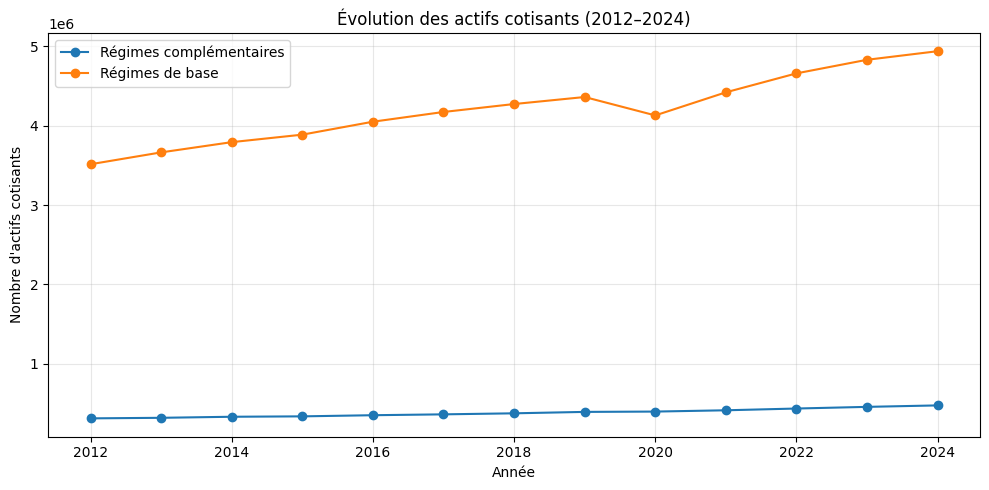

In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Charger les données
df = pd.read_csv(
    Path("data cleaning") / "master_dataset_indicators.csv"
)

# Premier graphique : actifs cotisants
plt.figure(figsize=(10, 5))

for regime in df["regime"].unique():
    data = df[df["regime"] == regime].sort_values("annee")
    plt.plot(
        data["annee"],
        data["actifs_cotisants"],
        marker="o",
        label=regime
    )

plt.title("Évolution des actifs cotisants (2012–2024)")
plt.xlabel("Année")
plt.ylabel("Nombre d'actifs cotisants")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



RÉGIME : Régimes complémentaires
                               count       mean       std        min        25%        50%        75%        max
actifs_cotisants                13.0  385258.08  52586.96  315574.00  340821.00  379076.00  417177.00  478623.00
beneficiaires                   13.0  182413.31  24784.64  145828.00  162228.00  181210.00  201997.00  220337.00
cotisations                     13.0    8202.11   2325.30    5395.57    6224.46    7948.27    9436.62   12512.29
prestations                     13.0    5283.44   1231.74    3381.50    4349.95    5085.05    6322.75    7233.08
placements                      13.0   56210.96  20881.23   27254.90   39161.44   55059.32   71866.14   92196.28
ratio_demographique             13.0       2.11      0.04       2.06       2.09       2.11       2.14       2.17
solde_cotisations_prestations   13.0    2918.67   1129.88    1570.52    2014.07    2863.22    3113.87    5279.21
taux_couverture_pct             13.0     153.86      9.43     

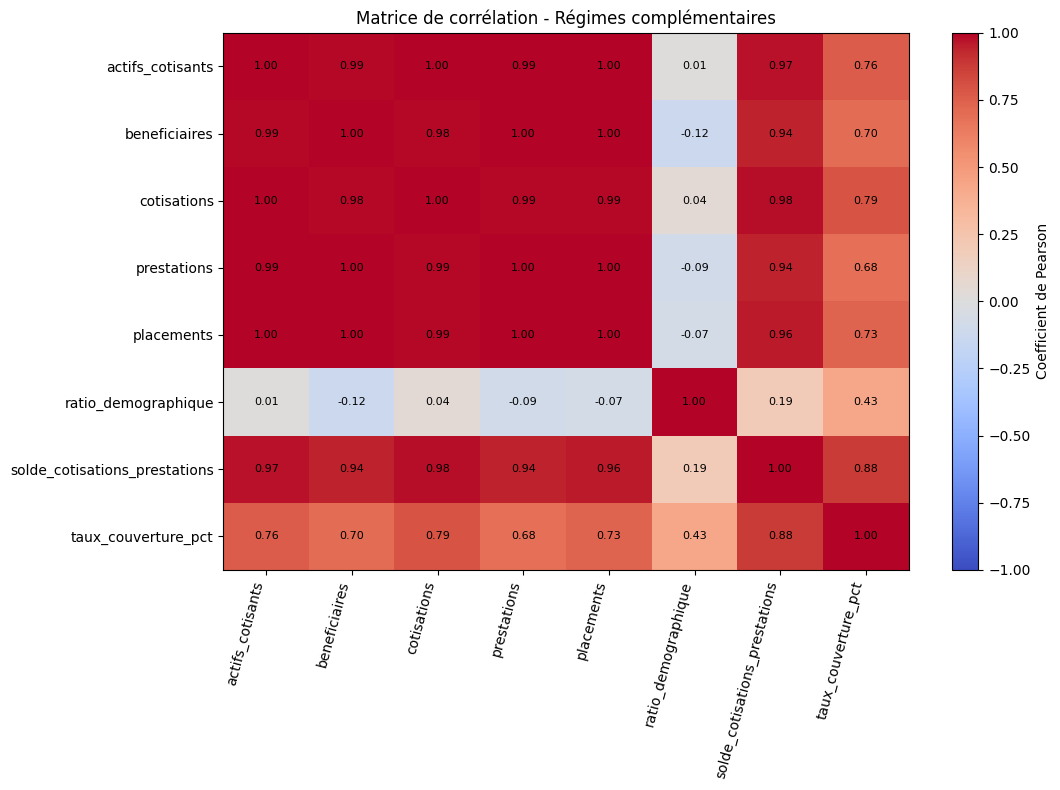


CORRÉLATION : Régimes de base
                               actifs_cotisants  beneficiaires  cotisations  prestations  placements  ratio_demographique  solde_cotisations_prestations  taux_couverture_pct
actifs_cotisants                           1.00           0.96         0.96         0.95        0.80                -0.86                          -0.82                -0.79
beneficiaires                              0.96           1.00         0.99         1.00        0.82                -0.97                          -0.91                -0.83
cotisations                                0.96           0.99         1.00         0.99        0.76                -0.93                          -0.85                -0.75
prestations                                0.95           1.00         0.99         1.00        0.83                -0.97                          -0.92                -0.84
placements                                 0.80           0.82         0.76         0.83        1.0

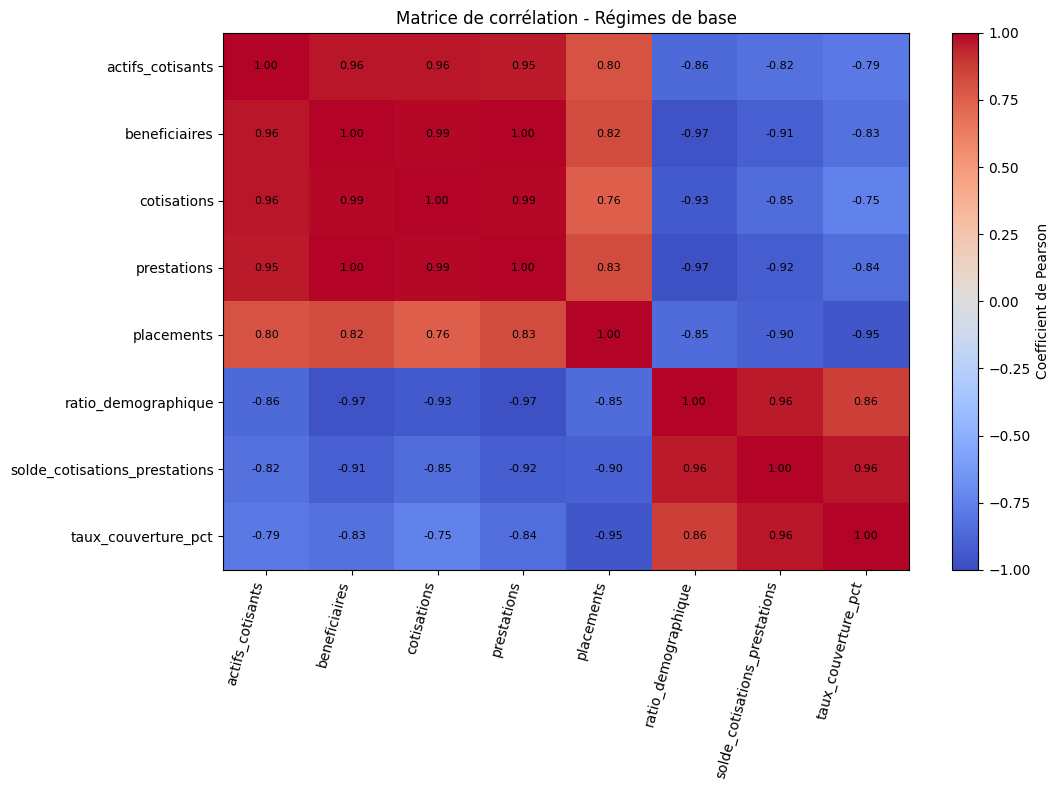


Matrices de corrélation enregistrées.


In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

dossier = Path("data cleaning")
df = pd.read_csv(dossier / "master_dataset_indicators.csv")

variables = [
    "actifs_cotisants",
    "beneficiaires",
    "cotisations",
    "prestations",
    "placements",
    "ratio_demographique",
    "solde_cotisations_prestations",
    "taux_couverture_pct"
]

# 1. Statistiques descriptives
for regime in df["regime"].unique():
    sous_df = df[df["regime"] == regime]

    print("\nRÉGIME :", regime)
    print(
        sous_df[variables]
        .describe()
        .round(2)
        .T
        .to_string()
    )

# 2. Matrices de corrélation par régime
for regime in df["regime"].unique():
    sous_df = df[df["regime"] == regime]

    correlation = sous_df[variables].corr(method="pearson")

    print("\nCORRÉLATION :", regime)
    print(correlation.round(2).to_string())

    # Heatmap sans seaborn
    fig, ax = plt.subplots(figsize=(11, 8))

    image = ax.imshow(
        correlation,
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
        aspect="auto"
    )

    ax.set_xticks(range(len(variables)))
    ax.set_xticklabels(variables, rotation=75, ha="right")
    ax.set_yticks(range(len(variables)))
    ax.set_yticklabels(variables)

    for i in range(len(variables)):
        for j in range(len(variables)):
            ax.text(
                j, i, f"{correlation.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=8
            )

    ax.set_title(f"Matrice de corrélation - {regime}")
    fig.colorbar(image, ax=ax, label="Coefficient de Pearson")
    plt.tight_layout()
    plt.show()

# 3. Corrélation enregistrée dans des fichiers CSV
for regime in df["regime"].unique():
    sous_df = df[df["regime"] == regime]
    correlation = sous_df[variables].corr()

    nom = (
        "correlation_base.csv"
        if regime == "Régimes de base"
        else "correlation_complementaires.csv"
    )

    correlation.to_csv(dossier / nom, encoding="utf-8-sig")

print("\nMatrices de corrélation enregistrées.")
